# Differential geometry 6: Geodesics

*Learning path: differential geometry, part 6 of 7.* [Index](README.md) · Previous: [Parallel transport](05-parallel-transport.ipynb) · Next: [The Riemann tensor](07-riemann-tensor.ipynb)

A **geodesic** is the straightest possible curve in a curved space: the path you trace if you walk straight ahead
without ever turning. Geodesics are also (locally) the shortest paths. In general relativity, planets and light rays
follow geodesics of spacetime, so this notebook is the bridge to physics. You will learn

* the geodesic equation and how Galileo writes it out,
* how to compute geodesics numerically and draw them,
* what geodesics look like on a sphere, a cone, a torus and in the hyperbolic plane,
* that geodesics which start parallel can meet: the first sign of curvature acting on paths.

## 1. The geodesic equation

A geodesic parallel transports its own velocity (part 5). Setting $V^a = \dot x^a$ in the transport equation gives

$$\ddot x^a = -\Gamma^a{}_{bc}\,\dot x^b \dot x^c$$

`geodesics(g)` writes these equations out. In polar coordinates:

In [1]:
p = metric.generate(polar)
geodesics(p)

$$ds^2 = dr^2 + r^{2}\, d\phi^2$$

> `metric`: A metric with the given coordinates and components g_ab.

**Geodesic equations (' = d/ds along the curve)**

$$\begin{aligned}
\ddot{r} &= \dot{\phi}^{2} \, r \\
\ddot{\phi} &= -\frac{2 \, \dot{\phi} \, \dot{r}}{r}
\end{aligned}$$

> `geodesics`: The geodesic equations of a metric, with ' for d/ds.

The equations look complicated, but they describe straight lines. `geodesic(g, start, velocity, length, map)` solves
them numerically and draws the result through `map`, which turns coordinates into points to plot. Several rows of
velocities give several geodesics from the same start. Starting at $r = 1$, $\phi = 0$:

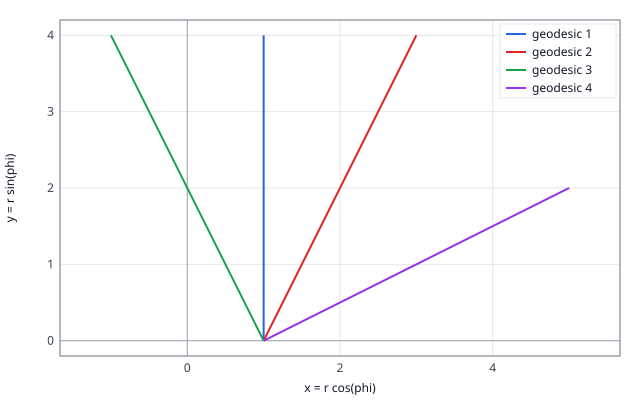

> `title`: A copy of plot p with a title or axis labels.

In [2]:
labels(geodesic(p, [1 0], [0 1; 0.5 1; -0.5 1; 1 0.5], 4, [r*cos(phi) r*sin(phi)]), "x = r cos(phi)", "y = r sin(phi)")

Straight lines, as they should be.

## 2. The sphere: great circles

On a sphere every geodesic is a great circle, which is why flight routes look curved on flat maps.

In [3]:
g = metric.generate(two-sphere)
geodesics(g)

$$ds^2 = r^{2}\, d\theta^2 + r^{2} \, \sin^{2}\left(\theta\right)\, d\phi^2$$

> `metric`: A metric with the given coordinates and components g_ab.

**Geodesic equations (' = d/ds along the curve)**

$$\begin{aligned}
\ddot{\theta} &= \dot{\phi}^{2} \, \sin\left(\theta\right) \, \cos\left(\theta\right) \\
\ddot{\phi} &= -\frac{2 \, \dot{\phi} \, \dot{\theta} \, \cos\left(\theta\right)}{\sin\left(\theta\right)}
\end{aligned}$$

> `geodesics`: The geodesic equations of a metric, with ' for d/ds.

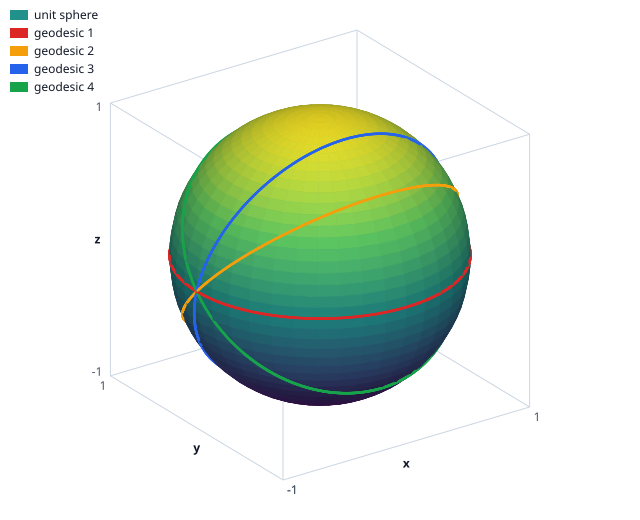

> `legend`: A copy of plot p with new names for its curves in the legend.

In [4]:
r = 1;
circles = geodesic(g, [pi/2 0], [0 1; 1 1; 1 0.3; 1, -1], 6.3, [sin(theta)*cos(phi) sin(theta)*sin(phi) cos(theta)]);
ball = surface(sin(theta)*cos(phi), sin(theta)*sin(phi), cos(theta), theta, 0, pi, phi, 0, 2*pi);
legend(show(ball, circles), "unit sphere")

## 3. Parallel lines that meet

Euclid's fifth postulate says that parallel lines never meet. On the sphere, start two walkers on the equator a short
distance apart, both heading due north. Their paths start out parallel, yet they meet at the north pole:

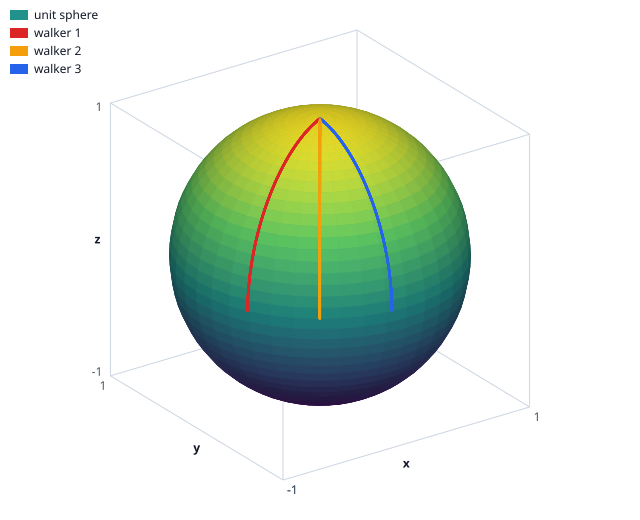

> `legend`: A copy of plot p with new names for its curves in the legend.

In [5]:
w1 = geodesic(g, [pi/2 3.6], [-1 0], pi/2, [sin(theta)*cos(phi) sin(theta)*sin(phi) cos(theta)]);
w2 = geodesic(g, [pi/2 4.1], [-1 0], pi/2, [sin(theta)*cos(phi) sin(theta)*sin(phi) cos(theta)]);
w3 = geodesic(g, [pi/2 4.6], [-1 0], pi/2, [sin(theta)*cos(phi) sin(theta)*sin(phi) cos(theta)]);
legend(show(ball, w1, w2, w3), "unit sphere", "walker 1", "walker 2", "walker 3")

Positive curvature focuses geodesics; negative curvature spreads them apart. In general relativity the same effect
is the tidal force of gravity.

## 4. The hyperbolic plane

In the upper half plane with $ds^2 = (dx^2 + dy^2)/y^2$, the geodesics are vertical lines and semicircles centred on
the $x$ axis. From the point $(0, 1)$ in several directions:

$$ds^2 = \frac{1}{y^{2}}\, dx^2 + \frac{1}{y^{2}}\, dy^2$$

> `metric`: A metric with the given coordinates and components g_ab.

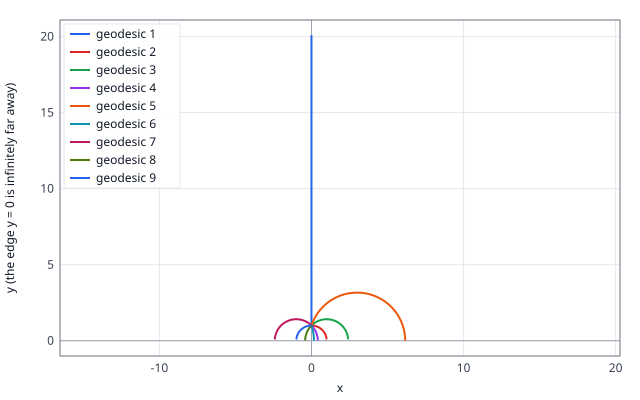

> `title`: A copy of plot p with a title or axis labels.

In [6]:
clear
h = metric.generate(hyperbolic)
fan = labels(geodesic(h, [0 1], [0 1; 1 0; 1 1; 1, -1; 1 3; 1, -3; -1 1; -1, -1; -1 0], 3, [x y]), "x", "y (the edge y = 0 is infinitely far away)")

Here infinitely many "lines" through a point miss a given line: the hyperbolic plane is the geometry where Euclid's
fifth postulate fails the other way. Its discovery, by Gauss, Bolyai and Lobachevsky [1][2], showed that geometry need not be
Euclidean, and paved the way for Einstein.

## 5. The cone

On a cone, a geodesic is a straight line on the unrolled paper. Rolled up, it comes in from far away, swings around
the tip and goes out again:

$$ds^2 = 2\, dw^2 + w^{2}\, dv^2$$

> `inducedmetric`: The metric induced by flat space on the surface (or curve, or hypersurface) x(u, v), y(u, v), z(u, v): the first fundamental form.

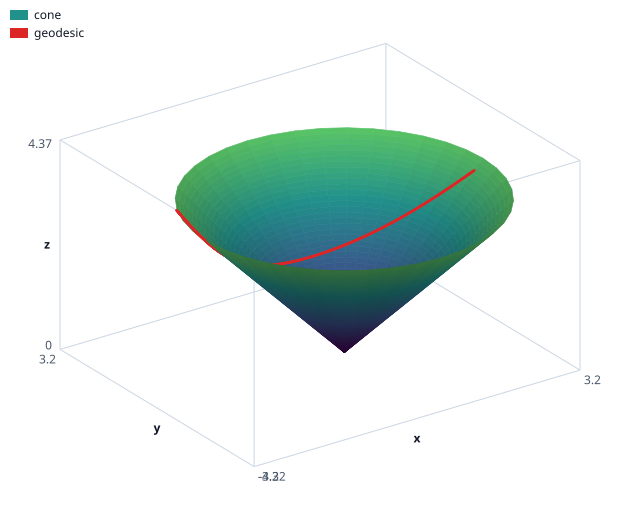

> `legend`: A copy of plot p with new names for its curves in the legend.

In [7]:
cone = [w*cos(v) w*sin(v) w];
c = inducedmetric(cone, [w v])
path = geodesic(c, [3 0], [-1 0.25], 6, [w*cos(v) w*sin(v) w]);
legend(show(surface(w*cos(v), w*sin(v), w, w, 0, 3.2, v, 0, 2*pi), path), "cone", "geodesic")

## 6. The torus

On a torus geodesics are much more varied. Starting on the outer equator, one goes around the tube, others wind
around the hole, and the one along the equator itself stays there:

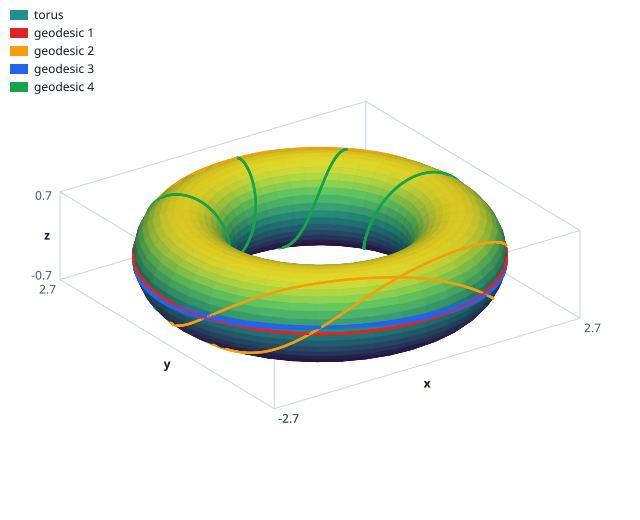

> `legend`: A copy of plot p with new names for its curves in the legend.

In [8]:
torus = [(R+a*cos(u))*cos(v) (R+a*cos(u))*sin(v) a*sin(u)];
t = inducedmetric(torus, [u v]);
R = 2;
a = 0.7;
paths = geodesic(t, [0 0], [0 1; 1 0.4; 0.3 1; 1 0.05], 25, torus);
ring = surface((R+a*cos(u))*cos(v), (R+a*cos(u))*sin(v), a*sin(u), u, 0, 2*pi, v, 0, 2*pi);
legend(show(ring, paths), "torus")

The geodesic that winds slowly ($\dot v = 0.05$) cannot get past the inner equator: it bounces between two circles,
like a ball rolling in a valley. Geodesics on surfaces of revolution conserve a quantity like angular momentum
(Clairaut's relation [3]), and the same conservation law will govern planetary orbits in general relativity.

## Summary

* Geodesics satisfy $\ddot x^a = -\Gamma^a{}_{bc}\dot x^b\dot x^c$; `geodesics(g)` shows the equations.
* `geodesic(g, start, velocities, length, map)` computes and draws them.
* Great circles on the sphere; semicircles in the hyperbolic plane; straight lines on the unrolled cone.
* Curvature makes initially parallel geodesics converge (positive) or diverge (negative).

**Try it:** on the torus, start on the *inner* equator, `[pi 0]`, with the same velocities. What changes?

Next: [The Riemann tensor](07-riemann-tensor.ipynb), curvature in any number of dimensions.

## Sources

Numbers in square brackets in the text refer to this list.

1. N. I. Lobachevsky, "On the principles of geometry", *Kazan Messenger* (1829–1830).
2. J. Bolyai, *Appendix scientiam spatii absolute veram exhibens*, appendix to F. Bolyai, *Tentamen* (1832). English: R. Bonola, *Non-Euclidean Geometry*, Dover (1955), which also documents Gauss's unpublished work.
3. M. P. do Carmo, *Differential Geometry of Curves and Surfaces*, 2nd ed., Dover (2016). Section 4-4 (geodesics, Clairaut's relation, geodesics of surfaces of revolution).